# 01 · Prepare the Khmer consonant dataset

**Phase 1 of the project: raw scans → clean, labelled 64×64 image dataset.**

Each collection sheet has 33 boxes, one per Khmer consonant (ក … អ), and 4 black corner squares used to straighten the page. This notebook:

1. checks `data/manifest.csv` against the raw scans,
2. straightens every page and crops the 33 letters,
3. splits the data **by writer** into train / val / test,
4. runs quality checks and packs `outputs/dataset.zip`.

| Input (in git) | Output (not in git, rebuilt by this notebook) |
|---|---|
| `data/raw/scan_###.pdf/.jpg`: untouched scans | `outputs/dataset/images/<id>_<letter>/*.png` |
| `data/manifest.csv`: which page belongs to which writer | `outputs/dataset/labels.csv` |
| | `outputs/dataset/_debug/`: straightened pages |
| | `outputs/dataset.zip` |

Run all cells from top to bottom. The notebook never modifies anything in `data/`.

## 1. Setup

Install the dependencies once (from the project root): `pip install -r requirements.txt`.
Or uncomment the line below to install them from inside the notebook.

In [1]:
# %pip install -q -r ../requirements.txt

In [2]:
import random, shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pymupdf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# Works whether the notebook is started from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR  = ROOT / "data" / "raw"
MANIFEST = ROOT / "data" / "manifest.csv"
OUT_DIR  = ROOT / "outputs" / "dataset"

assert RAW_DIR.is_dir() and MANIFEST.is_file(), f"Run this from the project folder. Looked in {ROOT}"
print("Project root:", ROOT)

Project root: /Users/macos/Documents/School/TestCrop


## 2. Settings

In [3]:
DPI           = 300     # resolution used to render PDF pages
IMG_SIZE      = 64      # output letter images are IMG_SIZE x IMG_SIZE
SPLIT         = {"train": 0.70, "val": 0.15, "test": 0.15}   # split by WRITER, not by image
SEED          = 42      # fixed so everybody on the team gets the same split
MIN_PER_CLASS = 30      # warn when a letter has fewer images than this

ROMAN   = "kor khor ko kho ngo chor chhor cho chho nho dor tthor do ttho nor tor thor to tho no bor phor po pho mo yo ro lo vo sor hor lor or".split()
LETTERS = list("កខគឃងចឆជឈញដឋឌឍណតថទធនបផពភមយរលវសហឡអ")
assert len(ROMAN) == len(LETTERS) == 33
IMG_EXT = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".webp"}

## 3. Load and check the manifest

`data/manifest.csv` has **one row per page**: `file, page, writer_id, sheet_no, note`.
This is how files that mix several people, and people whose sheets are spread over several files, are handled:

* several writers in one file → several rows for the same `file`, each with its own `writer_id`
* one writer over several files or pages → several rows with the same `writer_id`

The check below stops if a file is missing, a page does not exist, or a page is listed twice, and it lists any page that is in no row.

In [4]:
def n_pages(path):
    if path.suffix.lower() in IMG_EXT:
        return 1
    with pymupdf.open(path) as d:
        return len(d)

man = pd.read_csv(MANIFEST, dtype={"writer_id": str}, keep_default_na=False)
man["page"] = man["page"].astype(int)
man["sheet_no"] = man["sheet_no"].astype(int)

errors = []
for i, r in man.iterrows():
    p = RAW_DIR / r.file
    if not p.exists():
        errors.append(f"row {i + 2}: {r.file} not found in data/raw")
    elif not 1 <= r.page <= n_pages(p):
        errors.append(f"row {i + 2}: {r.file} has no page {r.page}")
dups = man[man.duplicated(["file", "page"], keep=False)]
errors += [f"{r.file} page {r.page} is listed more than once" for r in dups.itertuples()]
dup_sheet = man[man.duplicated(["writer_id", "sheet_no"], keep=False)]
errors += [f"{r.writer_id} sheet {r.sheet_no} is listed more than once" for r in dup_sheet.itertuples()]

listed = set(zip(man.file, man.page))
raw_files = sorted(p for p in RAW_DIR.iterdir() if p.suffix.lower() in IMG_EXT | {".pdf"})
unlisted = [f"{p.name} p{k}" for p in raw_files for k in range(1, n_pages(p) + 1) if (p.name, k) not in listed]

print(f"{len(raw_files)} raw files, {len(man)} pages, {man.writer_id.nunique()} writers")
print("Pages not in the manifest:", unlisted or "none")
assert not errors, "Fix data/manifest.csv:\n" + "\n".join(errors)
print("Manifest OK")

man.groupby("writer_id").agg(pages=("page", "size"), files=("file", lambda s: ", ".join(sorted(set(s)))))

29 raw files, 36 pages, 29 writers
Pages not in the manifest: none
Manifest OK


,pages,files
writer_id,,
w01,2,"scan_001.pdf, scan_002.pdf"
w02,1,scan_003.jpg
w03,1,scan_004.pdf
w04,1,scan_005.pdf
w05,1,scan_006.pdf
w06,1,scan_007.pdf
w07,1,scan_008.pdf
w08,1,scan_009.pdf
w09,2,scan_010.pdf


## 4. Helper functions

* `load_page` renders a PDF page, or opens a photo (fixing phone rotation), as a grayscale image.
* `straighten` finds the 4 corner squares and warps the page to a fixed size.
* `cell_box` gives the writing area of box *k* on the straightened page.
* `letter_image` turns the ink in a box into a centred 64×64 image (dark ink on white). It returns `None` for an empty box.

In [5]:
PX = 10                      # pixels per mm on the straightened page
W, H = 180 * PX, 237 * PX    # distance between the corner-square centres (mm * PX)

def load_page(file, page):
    path = RAW_DIR / file
    if path.suffix.lower() in IMG_EXT:
        return np.array(ImageOps.exif_transpose(Image.open(path)).convert("L"))
    with pymupdf.open(path) as doc:
        pix = doc[int(page) - 1].get_pixmap(dpi=DPI, colorspace=pymupdf.csGRAY)
        return np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width).copy()

def find_markers(gray):
    # Centres of the 4 black corner squares as TL, TR, BL, BR, or None.
    h, w = gray.shape
    for thresh in ("otsu", 110):
        if thresh == "otsu":
            _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        else:
            _, bw = cv2.threshold(gray, thresh, 255, cv2.THRESH_BINARY_INV)
        cnts, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        pts = []
        for c in cnts:
            a = cv2.contourArea(c)
            x, y, cw, ch = cv2.boundingRect(c)
            if 0.0002 * h * w < a < 0.01 * h * w and 0.7 < cw / ch < 1.4 and a / (cw * ch) > 0.85:
                pts.append((x + cw / 2, y + ch / 2))
        if len(pts) >= 4:
            p = np.array(pts, np.float32)
            s, d = p.sum(1), p[:, 0] - p[:, 1]
            return np.array([p[s.argmin()], p[d.argmax()], p[d.argmin()], p[s.argmax()]], np.float32)
    return None

def straighten(gray):
    m = find_markers(gray)
    if m is None:
        return None
    dst = np.array([[0, 0], [W, 0], [0, H], [W, H]], np.float32)
    return cv2.warpPerspective(gray, cv2.getPerspectiveTransform(m, dst), (W + 1, H + 1))

def cell_box(k):
    r, c = divmod(k, 5)
    x0, y0 = (10 + 32 * c) * PX, (5 + 32 * r) * PX
    return x0 + 2 * PX, y0 + 8 * PX, x0 + 30 * PX, y0 + 30 * PX

def ink_mask(page):
    return cv2.adaptiveThreshold(page, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 51, 15)

def letter_image(ink):
    ink = cv2.morphologyEx(ink, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    if ink.mean() / 255 < 0.003:
        return None
    ys, xs = np.where(ink > 0)
    ink = ink[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = ink.shape
    s = max(h, w); pad = int(0.15 * s)
    sq = np.zeros((s + 2 * pad, s + 2 * pad), np.uint8)
    oy, ox = pad + (s - h) // 2, pad + (s - w) // 2
    sq[oy:oy + h, ox:ox + w] = ink
    return 255 - cv2.resize(sq, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

## 5. Check the crop boxes on one page

The red boxes should sit inside the writing areas. Change `CHECK_ROW` to look at another page; row 2 is the phone photo.

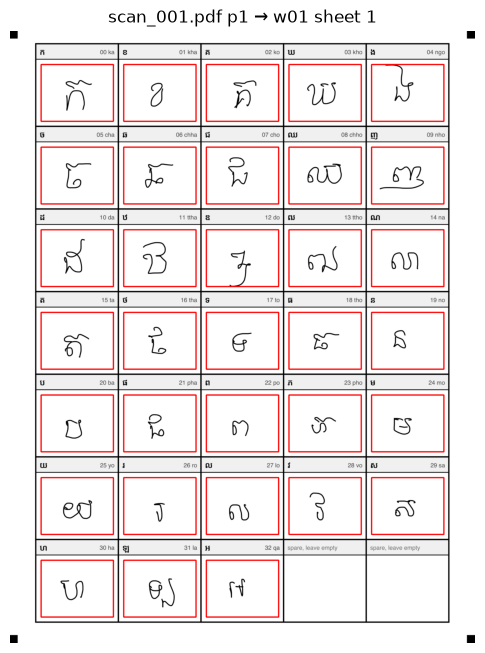

In [6]:
CHECK_ROW = 0
r = man.iloc[CHECK_ROW]
page = straighten(load_page(r.file, r.page))
if page is None:
    print(f"Corner squares NOT found on {r.file} page {r.page}. The page must be upright with all 4 squares visible.")
else:
    vis = cv2.cvtColor(page, cv2.COLOR_GRAY2BGR)
    for k in range(33):
        x0, y0, x1, y1 = cell_box(k)
        cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 0, 255), 3)
    plt.figure(figsize=(6, 8)); plt.imshow(vis[:, :, ::-1]); plt.axis("off")
    plt.title(f"{r.file} p{r.page} → {r.writer_id} sheet {r.sheet_no}"); plt.show()

## 6. Crop every page

Images are named `<writer_id>_s<sheet_no>_<label_id>.png`, for example `w10_s3_07.png`. Empty boxes are skipped and listed.
The straightened pages are saved to `outputs/dataset/_debug/` so you can look at them.

In [7]:
shutil.rmtree(OUT_DIR, ignore_errors=True)
(OUT_DIR / "_debug").mkdir(parents=True)

rows, problems = [], []
for r in man.itertuples():
    page = straighten(load_page(r.file, r.page))
    if page is None:
        problems.append(f"{r.file} p{r.page}: corner squares not found, page skipped")
        continue
    tag = f"{r.writer_id}_s{r.sheet_no}"
    cv2.imwrite(str(OUT_DIR / "_debug" / f"{tag}.png"), page)
    ink = ink_mask(page)
    for k in range(33):
        x0, y0, x1, y1 = cell_box(k)
        img = letter_image(ink[y0:y1, x0:x1])
        if img is None:
            problems.append(f"{r.file} p{r.page} ({tag}): box {k:02d} {ROMAN[k]} is empty")
            continue
        rel = f"images/{k:02d}_{ROMAN[k]}/{tag}_{k:02d}.png"
        (OUT_DIR / rel).parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(OUT_DIR / rel), img)
        rows.append(dict(filepath=rel, label_id=k, letter=LETTERS[k], romanization=ROMAN[k],
                         writer_id=r.writer_id, sheet_no=r.sheet_no, source_file=r.file, source_page=r.page))

df = pd.DataFrame(rows)
print(f"{len(df)} letter images from {df.writer_id.nunique()} writers, {len(man)} pages")
print(f"{len(problems)} problem(s)")
for p in problems:
    print("  -", p)

1188 letter images from 29 writers, 36 pages
0 problem(s)


## 7. Split by writer

All images of one writer go into **one** split. The test set therefore only contains handwriting the model has never seen.
The split is fixed by `SEED`, so it is the same on every computer.

In [8]:
writers = sorted(df.writer_id.unique())
random.Random(SEED).shuffle(writers)
n = len(writers)
n_val  = max(1, round(SPLIT["val"] * n))
n_test = max(1, round(SPLIT["test"] * n))
assert n - n_val - n_test >= 1, "Not enough writers for a train/val/test split. Collect more sheets."
split_of = {w: "val" if i < n_val else "test" if i < n_val + n_test else "train" for i, w in enumerate(writers)}
df["split"] = df.writer_id.map(split_of)

df.to_csv(OUT_DIR / "labels.csv", index=False, encoding="utf-8-sig")
summary = df.groupby("split").agg(writers=("writer_id", "nunique"), images=("filepath", "size"))
print(summary.to_string(), "\n")
for s in ["train", "val", "test"]:
    print(f"{s:5}:", ", ".join(sorted(w for w, v in split_of.items() if v == s)))

       writers  images
split                 
test         4     132
train       21     891
val          4     165 

train: w01, w02, w03, w04, w05, w08, w09, w10, w12, w14, w16, w17, w18, w20, w21, w24, w25, w26, w27, w28, w29
val  : w11, w15, w19, w23
test : w06, w07, w13, w22


## 8. Quality check (do not skip)

* **Bar chart:** every letter should have about the same number of images.
* **Image grid:** each row is one letter (kor at the top, or at the bottom), so a wrong or messy crop stands out.

Write down the file names of bad images, delete them from `outputs/dataset/images/`, then run section 9.

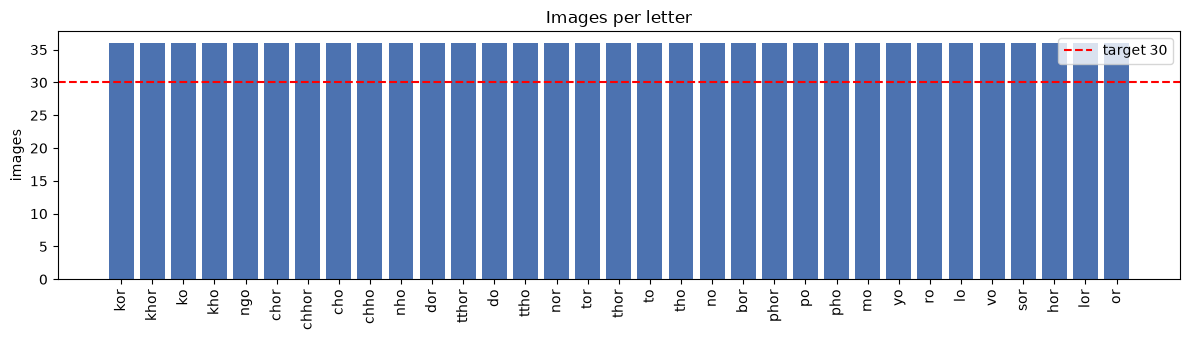

All letters reach the target.

Images per writer:
writer_id  split
w01        train     66
w02        train     33
w03        train     33
w04        train     33
w05        train     33
w06        test      33
w07        test      33
w08        train     33
w09        train     66
w10        train    132
w11        val       66
w12        train     33
w13        test      33
w14        train     33
w15        val       33
w16        train     33
w17        train     33
w18        train     66
w19        val       33
w20        train     33
w21        train     33
w22        test      33
w23        val       33
w24        train     33
w25        train     33
w26        train     33
w27        train     33
w28        train     33
w29        train     33


In [9]:
counts = df.groupby(["label_id", "romanization"]).size().reset_index(name="n")
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(counts.romanization, counts.n, color="#4C72B0")
ax.axhline(MIN_PER_CLASS, color="red", ls="--", label=f"target {MIN_PER_CLASS}")
ax.set_ylabel("images"); ax.set_title("Images per letter"); ax.legend()
plt.xticks(rotation=90); plt.tight_layout(); plt.show()
low = counts[counts.n < MIN_PER_CLASS]
print(f"{len(low)} of 33 letters are below the target of {MIN_PER_CLASS} images. Collect more sheets." if len(low) else "All letters reach the target.")

print("\nImages per writer:")
print(df.groupby(["writer_id", "split"]).size().rename("images").to_string())

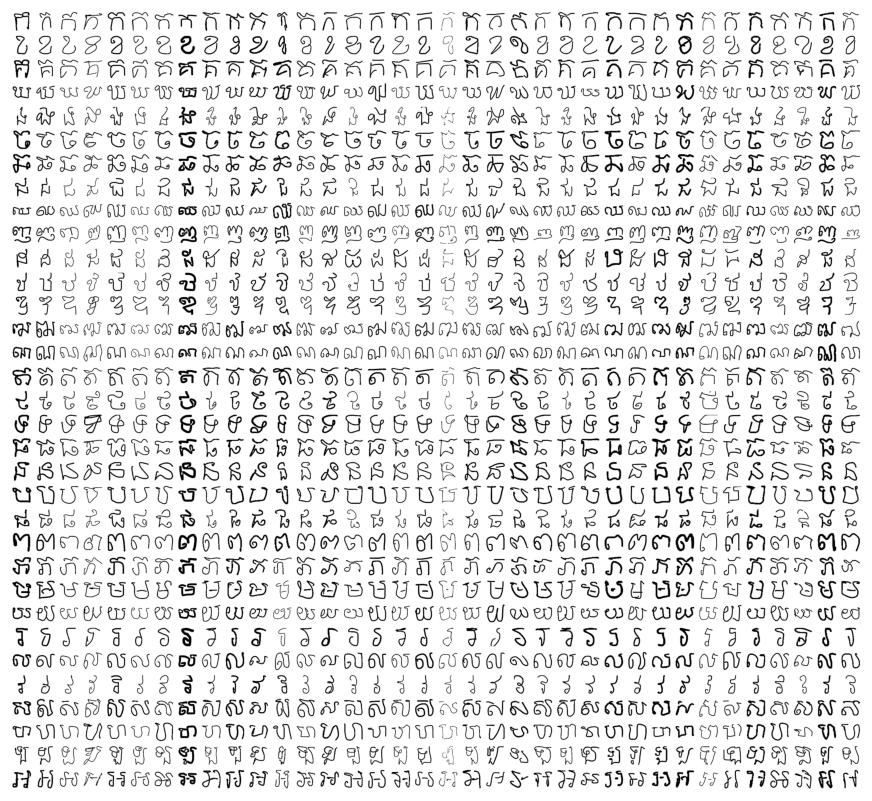

In [12]:
PER_ROW = 36
strips = []
for k in range(33):
    files = df[df.label_id == k].sample(frac=1, random_state=0).filepath.tolist()[:PER_ROW]
    imgs = [cv2.imread(str(OUT_DIR / f), cv2.IMREAD_GRAYSCALE) for f in files]
    imgs += [np.full((IMG_SIZE, IMG_SIZE), 255, np.uint8)] * (PER_ROW - len(imgs))
    strips.append(np.hstack(imgs))
plt.figure(figsize=(11, 25)); plt.imshow(np.vstack(strips), cmap="gray"); plt.axis("off"); plt.show()

## 9. Rebuild labels and zip the dataset

Run this after deleting any bad images: rows whose image no longer exists are dropped from `labels.csv`.

In [11]:
labels = pd.read_csv(OUT_DIR / "labels.csv", encoding="utf-8-sig", dtype={"writer_id": str})
labels = labels[labels.filepath.map(lambda f: (OUT_DIR / f).exists())]
labels.to_csv(OUT_DIR / "labels.csv", index=False, encoding="utf-8-sig")

zip_path = shutil.make_archive(str(OUT_DIR), "zip", OUT_DIR)
print(f"{len(labels)} images kept")
print(labels.groupby("split").size().to_string())
print("Created", Path(zip_path).relative_to(ROOT))

1188 images kept
split
test     132
train    891
val      165
Created outputs/dataset.zip


## 10. Result and next phase

`outputs/dataset/labels.csv` columns:

| column | meaning |
|---|---|
| `filepath` | image path relative to `outputs/dataset/` |
| `label_id` | 0–32, the class index (ក = 0 … អ = 32) |
| `letter`, `romanization` | the consonant and its romanized name |
| `writer_id` | anonymous writer ID from the manifest |
| `sheet_no` | which sheet of that writer |
| `source_file`, `source_page` | the raw scan the image came from (for tracing errors) |
| `split` | `train` / `val` / `test`, assigned by writer |

**Adding new scans:** put the files in `data/raw/` as the next `scan_###` number, add one row per page to `data/manifest.csv` (give a new person the next `wNN` ID), and run this notebook again.